Thresholds found : [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
train N=1000  test N=1000  window=[250:500]  (250 tokens)


/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


  thr=0.10  train_CE=2.5924  test_CE=2.5973
  thr=0.20  train_CE=2.6383  test_CE=2.6438
  thr=0.30  train_CE=2.6467  test_CE=2.6516
  thr=0.40  train_CE=2.7351  test_CE=2.7353
  thr=0.50  train_CE=2.6357  test_CE=2.6472
  thr=0.60  train_CE=2.4805  test_CE=2.4906
  thr=0.70  train_CE=2.2532  test_CE=2.2645
  thr=0.80  train_CE=1.9328  test_CE=1.9403
  thr=0.90  train_CE=1.5165  test_CE=1.5277


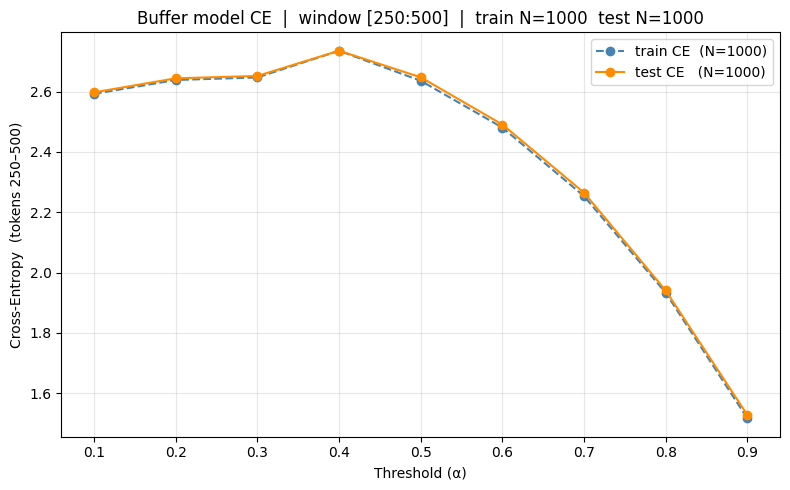

Saved → ce_vs_threshold.png


In [2]:
# ── SETTINGS ─────────────────────────────────────────────────────────────────
DATA_DIR      = '../4.training_for_oracle/dataset'
MODELS_DIR    = 'buffer models'
DEVICE        = 'cuda:3'

N_SEQS_TRAIN  = 1000   # sequences (first N) from train split for CE evaluation
N_SEQS_TEST   = 1000   # sequences (first N) from test  split for CE evaluation
TOKEN_START   = 250    # context window: evaluate CE from this token index ...
TOKEN_END     = 500    # ... to this token index (exclusive)  → last 250 tokens by default
# ─────────────────────────────────────────────────────────────────────────────

import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device(DEVICE)

# ── Model (must match train_buffer.py exactly) ────────────────────────────────
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None:
            scores = scores + mask
        attn_out = self.W_o(torch.bmm(F.softmax(scores, dim=-1), V))
        return torch.cat([x, attn_out], dim=-1), scores


class DisentangledTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, bias=False):
        super().__init__()
        self.total_vocab = total_vocab
        self.seq_len     = seq_len
        self.initial_dim = total_vocab + seq_len
        self.layer1 = ConcatAttentionBlock(self.initial_dim, attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + attn_dim, attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * attn_dim, total_vocab, bias=bias)

    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, _ = self.layer1(s, mask)
        s, _ = self.layer2(s, mask)
        return self.fc_out(s)


# ── Helpers ───────────────────────────────────────────────────────────────────
def load_data(split, thr):
    n_cap = N_SEQS_TRAIN if split == "train" else N_SEQS_TEST
    blob  = torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)
    N     = min(n_cap, blob['x'].shape[0])
    blob['x'] = blob['x'][:N]; blob['y'] = blob['y'][:N]
    if 'transitions' in blob: blob['transitions'] = blob['transitions'][:N]
    return blob['x'], blob['y'], int(blob['seq_len']), int(blob['total_vocab']), blob


def load_model(thr, seq_len, total_vocab):
    attn_dim = total_vocab + seq_len
    model = DisentangledTransformer(total_vocab, seq_len, attn_dim, bias=True).to(device)
    path  = os.path.join(MODELS_DIR, f'model_x_{thr}.pth')
    model.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    model.eval()
    return model


@torch.no_grad()
def compute_ce(model, x, y, total_vocab, batch_size=256):
    total_loss, n_tokens = 0.0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(device)
        yb = y[i:i+batch_size].to(device)
        logits = model(xb)[:, TOKEN_START:TOKEN_END, :]   # [B, window, V]
        yb_w   = yb[:, TOKEN_START:TOKEN_END]              # [B, window]
        loss   = F.cross_entropy(
            logits.reshape(-1, total_vocab),
            yb_w.reshape(-1),
            reduction='sum'
        )
        total_loss += loss.item()
        n_tokens   += yb_w.numel()
    return total_loss / n_tokens


# ── Discover thresholds from saved models ─────────────────────────────────────
thresholds = sorted(
    float(f[len('model_x_'):-len('.pth')])
    for f in os.listdir(MODELS_DIR)
    if f.startswith('model_x_') and f.endswith('.pth')
)
print(f'Thresholds found : {thresholds}')
print(f'train N={N_SEQS_TRAIN}  test N={N_SEQS_TEST}  window=[{TOKEN_START}:{TOKEN_END}]  ({TOKEN_END-TOKEN_START} tokens)')

# ── Evaluate ──────────────────────────────────────────────────────────────────
train_ce, test_ce = [], []
blobs_tr, blobs_te = {}, {}   # full blobs keyed by threshold (reused by cell 2)

for thr in thresholds:
    x_tr, y_tr, seq_len, total_vocab, blob_tr = load_data('train', thr)
    x_te, y_te, _,       _,           blob_te = load_data('test',  thr)
    blobs_tr[thr] = blob_tr;  blobs_te[thr] = blob_te
    model = load_model(thr, seq_len, total_vocab)

    ce_tr = compute_ce(model, x_tr, y_tr, total_vocab)
    ce_te = compute_ce(model, x_te, y_te, total_vocab)
    train_ce.append(ce_tr)
    test_ce.append(ce_te)
    print(f'  thr={thr:.2f}  train_CE={ce_tr:.4f}  test_CE={ce_te:.4f}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, train_ce, 'o--', color='steelblue',  label=f'train CE  (N={N_SEQS_TRAIN})')
ax.plot(thresholds, test_ce,  'o-',  color='darkorange', label=f'test CE   (N={N_SEQS_TEST})')
ax.set_xlabel('Threshold (α)')
ax.set_ylabel(f'Cross-Entropy  (tokens {TOKEN_START}–{TOKEN_END})')
ax.set_title(f'Buffer model CE  |  window [{TOKEN_START}:{TOKEN_END}]  |  train N={N_SEQS_TRAIN}  test N={N_SEQS_TEST}')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'ce_vs_threshold.png'), dpi=150)
plt.show()
print('Saved → ce_vs_threshold.png')


  thr=0.10  W*=4.0328  alp=2.5494
  thr=0.20  W*=3.5847  alp=2.5912
  thr=0.30  W*=3.2324  alp=2.5559
  thr=0.40  W*=2.9183  alp=2.4653
  thr=0.50  W*=2.6240  alp=2.3333
  thr=0.60  W*=2.3267  alp=2.1525
  thr=0.70  W*=2.0421  alp=1.9340
  thr=0.80  W*=1.7588  alp=1.6663
  thr=0.90  W*=1.4797  alp=1.3326


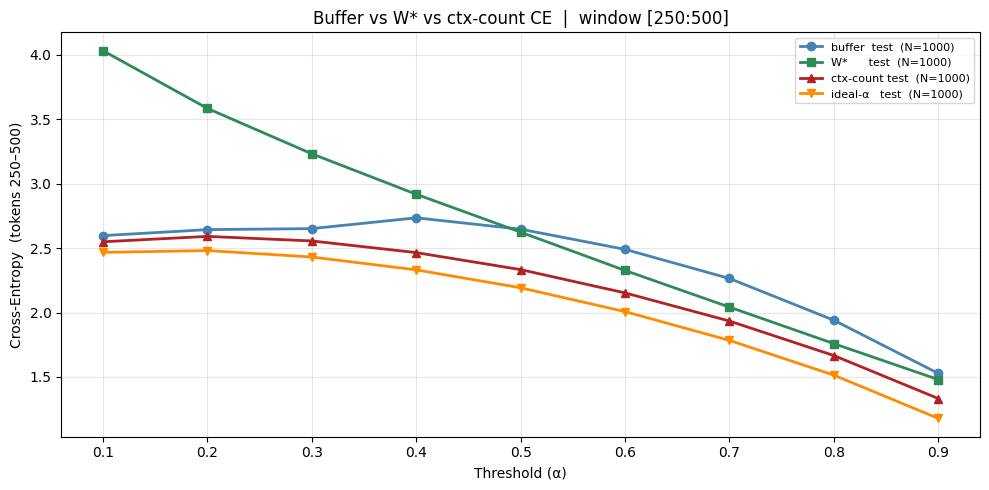

Saved → ce_comparison.png


In [ ]:
# ── SETTINGS ─────────────────────────────────────────────────────────────────
# TOKEN_START, TOKEN_END, N_SEQS_TRAIN, N_SEQS_TEST inherited from cell 1
INCLUDE_TEST         = True    # set False to hide test curves
INCLUDE_TRAIN        = False   # set False to hide train curves
WS_SIGMA             = 5.5     # temperature scale on W* logits (1.0 = raw)
# ─────────────────────────────────────────────────────────────────────────────

import numpy as np

# ── PerfectInductionTransformer (W*) ─────────────────────────────────────────
class _ConcatAttn(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        s = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: s = s + mask
        return torch.cat([x, self.W_o(torch.bmm(F.softmax(s, dim=-1), V))], dim=-1)


class PerfectInductionTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, vocab_set1):
        super().__init__()
        self.total_vocab = total_vocab
        self.seq_len     = seq_len
        self.vocab_set1  = vocab_set1
        self.initial_dim = total_vocab + seq_len
        self.attn_dim    = self.initial_dim
        self.layer1 = _ConcatAttn(self.initial_dim, self.attn_dim)
        self.layer2 = _ConcatAttn(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, total_vocab, bias=False)
        self._set_weights()

    def _set_weights(self):
        V = self.total_vocab; T = self.seq_len; D = self.attn_dim; V_r = self.vocab_set1
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        T1 = torch.zeros(D, D)
        for k in range(V_r, V): T1[k, :] = -1e9
        alpha_pos = 20.0
        for tq in range(T):
            for tk in range(T):
                if tq == tk: T1[V + tk, V + tq] = -1e9
                else:        T1[V + tk, V + tq] = -alpha_pos * (tq - tk)
        self.layer1.W_k.weight.data = T1.t()
        Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
        self.layer1.W_v.weight.data = Wv1
        self.layer1.W_o.weight.data = torch.eye(D)
        in2 = D + D
        Wq2 = torch.zeros(D, in2)
        Wq2[:V_r, :V_r]    = torch.eye(V_r) * (D ** 0.5) * 1000.0
        Wq2[:V_r, D:D+V_r] = torch.eye(V_r) * (D ** 0.5) * 50.0
        for v in range(V): Wq2[V_r, v] = (D ** 0.5) * 10.0
        self.layer2.W_q.weight.data = Wq2
        Wk2 = torch.zeros(D, in2); Wk2[:V, D:D+V] = torch.eye(V)
        for v in range(V_r, V): Wk2[V_r, v] = -50000.0
        self.layer2.W_k.weight.data = Wk2
        Wv2 = torch.zeros(D, in2); Wv2[:V, :V] = torch.eye(V)
        self.layer2.W_v.weight.data = Wv2
        self.layer2.W_o.weight.data = torch.eye(D)
        Wfc = torch.zeros(V, in2 + D); Wfc[:V, in2:in2+V] = torch.eye(V)
        self.fc_out.weight.data = Wfc

    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s = self.layer1(s, mask); s = self.layer2(s, mask)
        return self.fc_out(s)


# ── W* CE over window ─────────────────────────────────────────────────────────
@torch.no_grad()
def wstar_ce(blob, n_seqs, t_start, t_end, sigma=1.0, batch_size=128):
    x = blob['x'][:n_seqs];  y = blob['y'][:n_seqs]
    V = int(blob['total_vocab']); T = int(blob['seq_len'])
    model = PerfectInductionTransformer(V, T, int(blob['vocab_set1'])).to(device).eval()
    total_loss, n_tok = 0.0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(device);  yb = y[i:i+batch_size].to(device)
        logits = model(xb)[:, t_start:t_end, :] * sigma
        yb_w   = yb[:, t_start:t_end]
        total_loss += F.cross_entropy(logits.reshape(-1, V), yb_w.reshape(-1), reduction='sum').item()
        n_tok += yb_w.numel()
    del model
    if device.type == 'cuda': torch.cuda.empty_cache()
    return total_loss / n_tok


# ── Ideal (cheating) alpha CE — uses true Markov table ───────────────────────
def ideal_alpha_ce(blob, alpha, t_start, t_end):

    """Uses true Markov transition table from blob['transitions'].
    Effective Markov state at t = x[t] if signal, else last signal token seen.
    p[k1] = p[k2] = alpha/2  for the 2 true successors;
    p[noise_j] = (1-alpha)/n_noise for each noise token.
    """
    
    x_np  = blob['x'].numpy()
    y_np  = blob['y'].numpy()
    trans = blob['transitions']          # list[B] of dict {v: array([k1,k2])}
    V     = int(blob['total_vocab'])
    V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig
    B, T  = x_np.shape

    # Convert to array [B, V_sig, 2] once
    trans_arr = np.array([[trans[b][v] for v in range(V_sig)]
                          for b in range(B)], dtype=np.int64)

    total_ce, n_tok = 0.0, 0
    last_sig = np.zeros(B, dtype=np.int64)   # Markov state (default token 0)

    for t in range(t_end):
        is_sig   = x_np[:, t] < V_sig
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < t_start:
            continue

        s0 = trans_arr[np.arange(B), last_sig, 0]
        s1 = trans_arr[np.arange(B), last_sig, 1]

        p = np.zeros((B, V), dtype=np.float64)
        p[:, V_sig:] = (1.0 - alpha) / n_noise
        p[np.arange(B), s0] += alpha / 2
        p[np.arange(B), s1] += alpha / 2

        y_t = y_np[:, t]
        total_ce += (-np.log(np.maximum(p[np.arange(B), y_t], 1e-12))).sum()
        n_tok    += B

    return total_ce / n_tok


# ── Constructed-alpha CE over window ──────────────────────────────────────────
def alpha_ce(blob, alpha, t_start, t_end):
    
    """Occurrence-tracking context distribution CE.
    Query token:
      - if x[t] is signal  → use trans_counts[x[t], :] (current Markov state)
      - if x[t] is noise   → use trans_counts[last_ruled, :] (Markov state unchanged)
    Distribution: p[k] = cnt_s[k]/tot_s * alpha  (Laplace-smoothed, eps=1)
                  p[j] = (1-alpha)/n_noise        for each noise j
    """
    
    x_np  = blob['x'].numpy()
    y_np  = blob['y'].numpy()
    V     = int(blob['total_vocab'])
    V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig
    B, T  = x_np.shape

    trans_counts = np.zeros((B, V, V_sig), dtype=np.float64)
    pending      = np.zeros((B, V),        dtype=np.float64)
    last_ruled   = np.full(B, -1, dtype=np.int64)   # -1 = no signal token seen yet

    def _step(col):
        tok_col  = x_np[:, col]
        is_ruled = tok_col < V_sig
        ri = np.where(is_ruled)[0]
        if len(ri):
            rt = tok_col[ri]
            oh = (np.arange(V_sig) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0
            pending[ri, rt] = 1.0
            last_ruled[ri]  = rt        # track latest signal token per batch
        ni = np.where(~is_ruled)[0]
        if len(ni):
            pending[ni, tok_col[ni]] += 1.0

    for i in range(t_start):
        _step(i)

    eps = 1.0
    total_ce, n_tok = 0.0, 0

    for t in range(t_start, t_end):
        
        v        = x_np[:, t]
        is_sig_q = v < V_sig

        # noise query → fall back to last signal token (Markov state unchanged)
        query  = np.where(is_sig_q, v, np.maximum(last_ruled, 0))
        cnt    = trans_counts[np.arange(B), query]
        cnt_s  = cnt + eps
        tot_s  = cnt_s.sum(axis=1, keepdims=True)

        p = np.zeros((B, V), dtype=np.float64)
        p[:, :V_sig] = cnt_s / tot_s * alpha
        p[:, V_sig:] = (1.0 - alpha) / n_noise
        p = np.maximum(p, 1e-12)

        y_t = y_np[:, t]
        total_ce += (-np.log(p[np.arange(B), y_t])).sum()
        n_tok    += B

        _step(t)

    return total_ce / n_tok

# ── Evaluate ──────────────────────────────────────────────────────────────────
ws_te_ce,  alp_te_ce,  ialp_te_ce = [], [], []
ws_tr_ce,  alp_tr_ce,  ialp_tr_ce = [], [], []

for thr in thresholds:
    blob_te = blobs_te[thr]
    blob_te['threshold'] = thr   # ensure oracle_ce can read it

    _te_str = ''
    if INCLUDE_TEST:
        w_te  = wstar_ce(blob_te, N_SEQS_TEST,  TOKEN_START, TOKEN_END, sigma=WS_SIGMA)
        a_te  = alpha_ce(blob_te, thr, TOKEN_START, TOKEN_END)
        ia_te = ideal_alpha_ce(blob_te, thr, TOKEN_START, TOKEN_END)
        ws_te_ce.append(w_te);  alp_te_ce.append(a_te);  ialp_te_ce.append(ia_te)

    if INCLUDE_TRAIN:
        blob_tr = blobs_tr[thr]
        blob_tr['threshold'] = thr
        w_tr = wstar_ce(blob_tr, N_SEQS_TRAIN, TOKEN_START, TOKEN_END, sigma=WS_SIGMA)
        a_tr = alpha_ce(blob_tr, thr, TOKEN_START, TOKEN_END)
        ia_tr = ideal_alpha_ce(blob_tr, thr, TOKEN_START, TOKEN_END)
        ws_tr_ce.append(w_tr);  alp_tr_ce.append(a_tr);  ialp_tr_ce.append(ia_tr)
        _te_str2 = (f'  W*={w_te:.4f}/{w_tr:.4f}  alp={a_te:.4f}/{a_tr:.4f}'
                    if INCLUDE_TEST else
                    f'  W* tr={w_tr:.4f}  alp tr={a_tr:.4f}')
        print(f'  thr={thr:.2f}{_te_str2}')
    else:
        _te_str = f'  W*={w_te:.4f}  alp={a_te:.4f}'
    print(f'  thr={thr:.2f}{_te_str}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

# buffer (from cell 1)
if INCLUDE_TEST:
    ax.plot(thresholds, test_ce,    'o-',  color='steelblue',    linewidth=2, label=f'buffer  test  (N={N_SEQS_TEST})')
    ax.plot(thresholds, ws_te_ce,   's-',  color='seagreen',     linewidth=2, label=f'W*      test  (N={N_SEQS_TEST})')
    ax.plot(thresholds, alp_te_ce,  '^-',  color='firebrick',    linewidth=2, label=f'ctx-count test  (N={N_SEQS_TEST})')
    ax.plot(thresholds, ialp_te_ce, 'v-',  color='darkorange',   linewidth=2, label=f'ideal-α   test  (N={N_SEQS_TEST})')

if INCLUDE_TRAIN:
    ax.plot(thresholds, train_ce,   'o--', color='steelblue',  alpha=0.6, label=f'buffer  train (N={N_SEQS_TRAIN})')
    ax.plot(thresholds, ws_tr_ce,   's--', color='seagreen',   alpha=0.6, label=f'W*      train (N={N_SEQS_TRAIN})')
    ax.plot(thresholds, alp_tr_ce,  '^--', color='firebrick',  alpha=0.6, label=f'ctx-count train (N={N_SEQS_TRAIN})')
    ax.plot(thresholds, ialp_tr_ce, 'v--', color='darkorange', alpha=0.6, label=f'ideal-α   train (N={N_SEQS_TRAIN})')

ax.set_xlabel('Threshold (\u03b1)')
ax.set_ylabel(f'Cross-Entropy  (tokens {TOKEN_START}\u2013{TOKEN_END})')
ax.set_title(f'Buffer vs W* vs ctx-count CE  |  window [{TOKEN_START}:{TOKEN_END}]')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'ce_comparison.png'), dpi=150)
plt.show()
print('Saved \u2192 ce_comparison.png')


##### alpha implementable construction: 


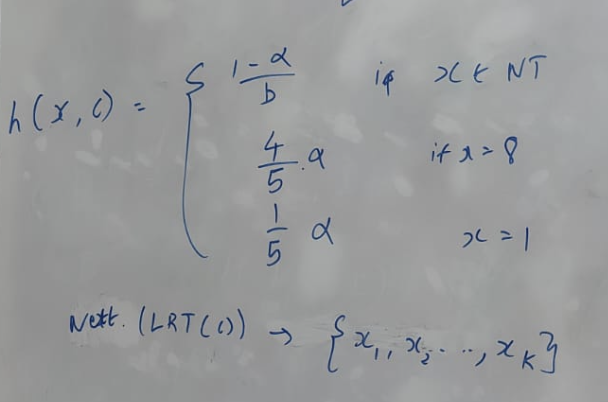

Seq 0  thr=0.7  split=test  range=[0,50)  T=500
hedge: sigma=5.5  eps=0.0

Markov transitions:
  0 -> {5, 4}
  1 -> {7, 2}
  2 -> {1, 3}
  3 -> {3, 0}
  4 -> {6, 9}
  5 -> {3, 8}
  6 -> {2, 0}
  7 -> {7, 4}
  8 -> {2, 8}
  9 -> {2, 7}

   pos  x[t]  y[t]    W*   ok    p_ws(y)   buf   p_buf(y)
  ----  ----  ----  ----  ---  ---------  ----  ---------
     0    18     5    18    ✗     0.0038     3     0.2336  <--FP
     1     5    14     5    ✗     0.0038     5     0.0000
     2    14     3     5    ✗     0.0038     5     0.0005
     3     3     3     3    ✓     0.3174     5     0.0152
     4     3     0     3    ✗     0.0038     3     0.0001
     5     0     5     0    ✗     0.0203     3     0.3858
     6     5     8     3    ✗     0.0203     0     0.0003
     7     8     8     3    ✗     0.1749     5     0.0000
     8     8    19     8    ✗     0.0038     5     0.0000
     9    19     2     8    ✗     0.0038     8     0.0022
    10     2    14     2    ✗     0.0203     5     0.0003
   

/tmp/ipykernel_3111010/2048773179.py:169: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


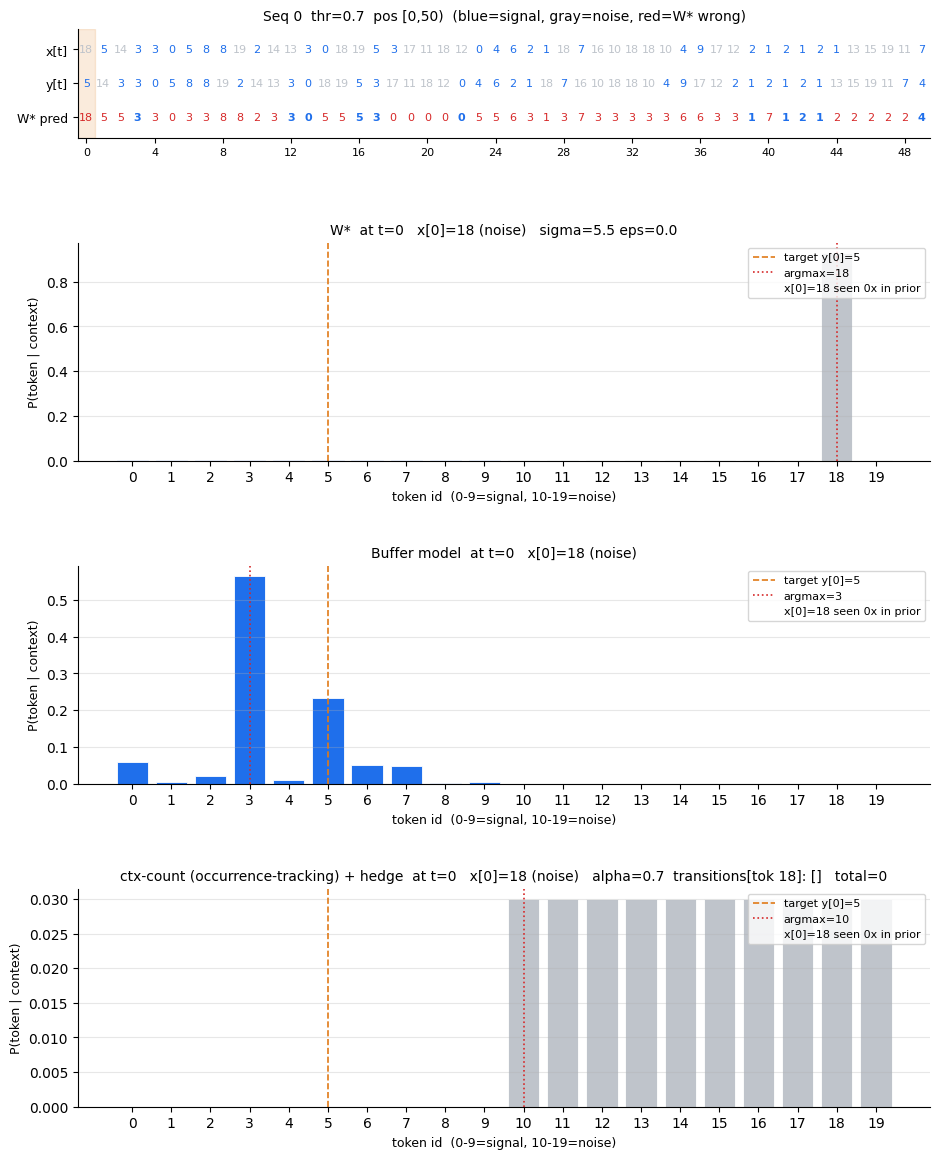

In [8]:
# ── SETTINGS ─────────────────────────────────────────────────────────────────
INSPECT_THRESH   = 0.7
SEQ_IDX          = 0       # which sequence to inspect
RANGE_START      = 0     # None → seq_len - 50
RANGE_END        = 50     # None → seq_len
FOCUS_POS        = 0    # None → RANGE_END - 1
INSPECT_SIGMA    = 5.5     # temperature for W* logits
INSPECT_EPSILON  = 0.0     # hedging weight
INSPECT_SPLIT    = 'test'  # 'test' or 'train'
# ─────────────────────────────────────────────────────────────────────────────

# load data for this threshold
_blob  = torch.load(os.path.join(DATA_DIR, INSPECT_SPLIT, f'data_x_{INSPECT_THRESH}.pt'), weights_only=False)
_x_all = _blob['x'];  _y_all = _blob['y']
_trans_all = _blob['transitions']
_V     = int(_blob['total_vocab']);  _V_sig = int(_blob['vocab_set1'])
_T     = int(_blob['seq_len'])

assert 0 <= SEQ_IDX < _x_all.shape[0], f'SEQ_IDX={SEQ_IDX} out of range'
_x_seq = _x_all[SEQ_IDX].to(device)
_y_seq = _y_all[SEQ_IDX].to(device)
_trans = _trans_all[SEQ_IDX]

_rs = max(0, _T - 50) if RANGE_START is None else max(0, int(RANGE_START))
_re = _T              if RANGE_END   is None else min(_T, int(RANGE_END))
_fp = _re - 1         if FOCUS_POS   is None else int(FOCUS_POS)
assert 0 <= _rs < _re <= _T, f'bad range [{_rs},{_re})'
assert 0 <= _fp < _T,         f'FOCUS_POS out of range'

# W* forward pass
_wstar = PerfectInductionTransformer(_V, _T, _V_sig).to(device).eval()
with torch.no_grad():
    _ws_logits = _wstar(_x_seq.unsqueeze(0)).squeeze(0)          # [T, V]
    _p_soft    = F.softmax(_ws_logits * INSPECT_SIGMA, dim=-1)
    _boost     = torch.zeros(_V, device=device, dtype=_p_soft.dtype)
    _boost[_V_sig:] = INSPECT_EPSILON / (_V - _V_sig)
    _ws_probs  = (1.0 - INSPECT_EPSILON) * _p_soft + _boost      # [T, V]
    _ws_pred   = _ws_probs.argmax(-1)
del _wstar
if device.type == 'cuda': torch.cuda.empty_cache()

# Buffer model forward pass
_buf_model = load_model(INSPECT_THRESH, _T, _V)
with torch.no_grad():
    _buf_logits = _buf_model(_x_seq.unsqueeze(0)).squeeze(0)      # [T, V]
    _buf_probs  = F.softmax(_buf_logits, dim=-1)
    _buf_pred   = _buf_probs.argmax(-1)
del _buf_model
if device.type == 'cuda': torch.cuda.empty_cache()

_x_np   = _x_seq.cpu().numpy()
_y_np   = _y_seq.cpu().numpy()
_ws_pb  = _ws_probs.cpu().numpy()
_ws_pr  = _ws_pred.cpu().numpy()
_buf_pb = _buf_probs.cpu().numpy()
_buf_pr = _buf_pred.cpu().numpy()

# ── text printout ─────────────────────────────────────────────────────────────
print(f'Seq {SEQ_IDX}  thr={INSPECT_THRESH}  split={INSPECT_SPLIT}  range=[{_rs},{_re})  T={_T}')
print(f'hedge: sigma={INSPECT_SIGMA}  eps={INSPECT_EPSILON}\n')
print('Markov transitions:')
for r in range(_V_sig):
    r1, r2 = int(_trans[r][0]), int(_trans[r][1])
    print(f'  {r} -> {{{r1}, {r2}}}')
print()
print(f'  {"pos":>4}  {"x[t]":>4}  {"y[t]":>4}  {"W*":>4}  {"ok":>3}  {"p_ws(y)":>9}  {"buf":>4}  {"p_buf(y)":>9}')
print(f'  {"-"*4}  {"-"*4}  {"-"*4}  {"-"*4}  {"-"*3}  {"-"*9}  {"-"*4}  {"-"*9}')
for t in range(_rs, _re):
    ok  = '\u2713' if _ws_pr[t] == _y_np[t] else '\u2717'
    mrk = '  <--FP' if t == _fp else ''
    print(f'  {t:>4}  {_x_np[t]:>4}  {_y_np[t]:>4}  {_ws_pr[t]:>4}  {ok:>3}  '
          f'{_ws_pb[t, _y_np[t]]:9.4f}  {_buf_pr[t]:>4}  {_buf_pb[t, _y_np[t]]:9.4f}{mrk}')
print(f'\n  W* accuracy [{_rs},{_re}): {(_ws_pr[_rs:_re]==_y_np[_rs:_re]).mean():.2%}')
print(f'  buf accuracy [{_rs},{_re}): {(_buf_pr[_rs:_re]==_y_np[_rs:_re]).mean():.2%}')

# expected continuations at FOCUS_POS
_fp_tok = int(_x_np[_fp])
_expected = (int(_trans[_fp_tok][0]), int(_trans[_fp_tok][1])) if _fp_tok < _V_sig else None

# prior-context tally
_prior_count = int((_x_np[:_fp] == _fp_tok).sum())
_next_ruled = []
for i in range(_fp):
    if int(_x_np[i]) != _fp_tok: continue
    for j in range(i+1, _T):
        if int(_x_np[j]) < _V_sig: _next_ruled.append(int(_x_np[j])); break

# ── figure ────────────────────────────────────────────────────────────────────
_BLUE = '#1f6feb'; _ORANGE = '#e07a18'; _GRAY = '#bfc4cb'
_RED  = '#d62828'; _GREEN  = '#2a9d4a'

# ── context-count distribution at FOCUS_POS (occurrence-tracking, matches alpha_ce) ──
# _fp_tok already defined above
_tr_cnt   = np.zeros((_V, _V_sig), dtype=np.float64)
_pend     = np.zeros(_V, dtype=np.float64)
_last_sig = -1   # last signal token seen in context
for _ii in range(_fp):
    _ti = int(_x_np[_ii])
    if _ti < _V_sig:
        _tr_cnt[:, _ti] += _pend
        _pend[:] = 0.0
        _pend[_ti] = 1.0
        _last_sig = _ti
    else:
        _pend[_ti] += 1.0
# if focus token is noise, use last signal token's distribution (Markov state unchanged)
_query_tok = _fp_tok if _fp_tok < _V_sig else max(_last_sig, 0)
_cnt_fp    = _tr_cnt[_query_tok]                                  # [V_sig]
_total_fp  = _cnt_fp.sum()
_p_sig     = (_cnt_fp / max(_total_fp, 1e-12) * INSPECT_THRESH
              if _total_fp > 0 else np.zeros(_V_sig))
_ctx_ph    = np.zeros(_V, dtype=np.float64)
_ctx_ph[:_V_sig] = _p_sig
_ctx_ph[_V_sig:] = (1.0 - INSPECT_THRESH) / (_V - _V_sig)
_ctx_ph    = np.maximum(_ctx_ph, 1e-12)
_ctx_pred = int(_ctx_ph.argmax())

_cols = _re - _rs
fig, axes = plt.subplots(4, 1, figsize=(max(11, _cols * 0.22), 14),
                          gridspec_kw={'height_ratios': [1, 2, 2, 2], 'hspace': 0.55})

# strip
ax_s = axes[0]
for j, t in enumerate(range(_rs, _re)):
    ax_s.text(j, 2, str(_x_np[t]),  ha='center', va='center', fontsize=8,
              color=(_BLUE if _x_np[t] < _V_sig else _GRAY))
    ax_s.text(j, 1, str(_y_np[t]),  ha='center', va='center', fontsize=8,
              color=(_BLUE if _y_np[t] < _V_sig else _GRAY))
    ax_s.text(j, 0, str(_ws_pr[t]), ha='center', va='center', fontsize=8,
              color=(_BLUE if _ws_pr[t] == _y_np[t] else _RED),
              fontweight=('bold' if _ws_pr[t] == _y_np[t] else 'normal'))
if _rs <= _fp < _re:
    ax_s.axvspan(_fp-_rs-0.5, _fp-_rs+0.5, color=_ORANGE, alpha=0.15)
ax_s.set_yticks([0,1,2]); ax_s.set_yticklabels(['W* pred','y[t]','x[t]'], fontsize=9)
ax_s.set_xticks(range(0,_cols,max(1,_cols//12)))
ax_s.set_xticklabels([str(_rs+i) for i in range(0,_cols,max(1,_cols//12))], fontsize=8)
ax_s.set_xlim(-0.5, _cols-0.5); ax_s.set_ylim(-0.6, 2.6)
ax_s.set_title(f'Seq {SEQ_IDX}  thr={INSPECT_THRESH}  pos [{_rs},{_re})  (blue=signal, gray=noise, red=W* wrong)', fontsize=10)
for s in ['top','right']: ax_s.spines[s].set_visible(False)

def _draw_bar(ax, p1d, pred_val, title):
    bar_colors = [_BLUE if k < _V_sig else _GRAY for k in range(_V)]
    if _expected:
        bar_colors[_expected[0]] = _GREEN; bar_colors[_expected[1]] = _GREEN
    ax.bar(range(_V), p1d, color=bar_colors, edgecolor='white', linewidth=0.6)
    ax.axvline(_y_np[_fp], color=_ORANGE, lw=1.2, ls='--', label=f'target y[{_fp}]={_y_np[_fp]}')
    ax.axvline(pred_val,   color=_RED,    lw=1.2, ls=':',  label=f'argmax={pred_val}')
    if _expected:
        ax.plot([], [], 's', color=_GREEN, ms=9, label=f'Markov-valid: {{{_expected[0]},{_expected[1]}}}')
    ax.plot([], [], ' ', label=f'x[{_fp}]={_fp_tok} seen {_prior_count}x in prior')
    ax.set_xticks(range(_V))
    ax.set_xlabel('token id  (0-9=signal, 10-19=noise)', fontsize=9)
    ax.set_ylabel('P(token | context)', fontsize=9)
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(axis='y', alpha=0.3)
    ax.set_title(title, fontsize=10)
    for s in ['top','right']: ax.spines[s].set_visible(False)

_chain = f'x[{_fp}]={_fp_tok} -> {{{_expected[0]},{_expected[1]}}}' if _expected else f'x[{_fp}]={_fp_tok} (noise)'
_draw_bar(axes[1], _ws_pb[_fp],  int(_ws_pr[_fp]),  f'W*  at t={_fp}   {_chain}   sigma={INSPECT_SIGMA} eps={INSPECT_EPSILON}')
_draw_bar(axes[2], _buf_pb[_fp], int(_buf_pr[_fp]), f'Buffer model  at t={_fp}   {_chain}')

# ctx-count bar (same distribution used in cell 1 alpha_ce curve)
_sig_cnt_str = ', '.join(f'{k}:{int(_cnt_fp[k])}' for k in range(_V_sig) if _cnt_fp[k] > 0)
_draw_bar(axes[3], _ctx_ph, _ctx_pred,
          f'ctx-count (occurrence-tracking) + hedge  at t={_fp}   {_chain}   '
          f'alpha={INSPECT_THRESH}  transitions[tok {_fp_tok}]: [{_sig_cnt_str}]   total={int(_total_fp)}')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, f'inspect_seq{SEQ_IDX}_thr{INSPECT_THRESH}_fp{_fp}.png'), dpi=150)
plt.show()
